# LLAMA Tokenizer

## Importing the libraries

In [12]:
import os
import json
import matplotlib.pyplot as plt 
from dotenv import load_dotenv
from huggingface_hub import login
from transformers import AutoTokenizer

## Loading HF Access Token

In [4]:
load_dotenv(override = True)
HF_TOKEN = os.getenv("HUGGINGFACE_ACCESS_TOKEN")
login(HF_TOKEN)

## Loading LLAMA's Tokenizer

In [ ]:
BASE_MODEL = "meta-llama/Llama-3.2-3B"
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

## Reading the dataset

In [ ]:
content = ""

with open("Dataset.jsonl", "r", encoding = "utf-8") as f:
    lines = f.readlines()
    for line in lines:
        line = json.loads(line)
        content += line["prompt"]
        content += line["completion"]
        content += "\n\n"

## Calculating Tokens Count

In [16]:
token_count = [len(tokenizer.encode(token, add_special_tokens = False)) for token in content.split("\n\n")]

In [ ]:
print(token_count[:10])

[229, 201, 266, 244, 201, 210, 186, 248, 247, 205]


## Visualising Results

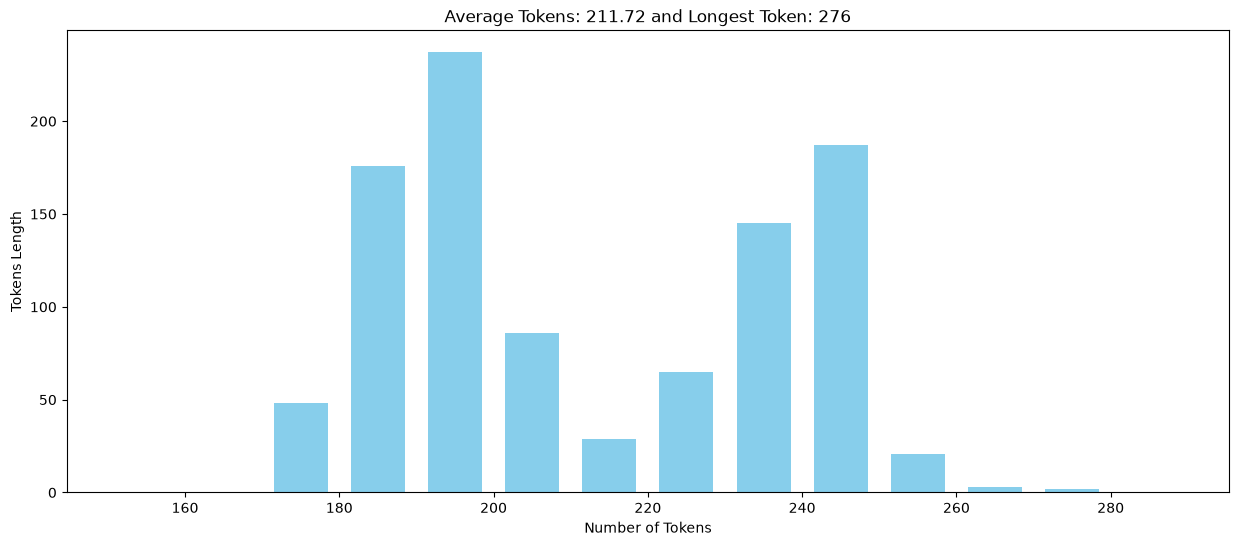

In [20]:
plt.figure(figsize = (15, 6))
plt.hist(token_count, rwidth = 0.7, color = "skyblue", bins = range(150, 300, 10))
plt.title(f"Average Tokens: {sum(token_count) / len(token_count):.2f} and Longest Token: {max(token_count)}")
plt.xlabel("Number of Tokens")
plt.ylabel("Tokens Length")
plt.show()